# Weighted PageRank (WPR) — Part 6
## How many match results agree with each ranking?
**Chakib Madcur · Progress update for the 11/15 meeting**

**Professor Dantsin's idea:** for each ranking, compute the **percentage of the results that are consistent with the order**.

1. Put all results of a season in a **results matrix**: one row and one column per player. The cell (row A, column B) holds the number of times A beat B.
2. Take a ranking (the ATP ranking or PageRank). A result is **consistent** if the **higher-ranked player won**, and **inconsistent** (an upset) if the lower-ranked player won.
3. **Percentage consistent** = consistent results ÷ all results. The ranking with the higher percentage agrees more with what happened on court.

Example: if the order is A, D, C, B and the season's results are *D beat B, B beat C, A beat D, C beat D*, then D–B and A–D are consistent and B–C and C–D are upsets: **2 of 4 = 50%**.

## Step 1 · Setup
Same data and the same PageRank program as Part 5: tour-level matches, a directed graph per season (loser → winner), *d* = 0.85, uniform restart. The new part is the results matrix and the percentage.

In [1]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

LOCAL = os.environ.get("LOCAL_DATA")   # optional folder with local copies of the files (faster); otherwise download
def get(url):
    p = os.path.join(LOCAL, url.split("/")[-1]) if LOCAL else None
    return p if p and os.path.exists(p) else url

SACKMANN = "https://raw.githubusercontent.com/Aneeshers/tennis-sackmann-archive/main/"   # copy of Jeff Sackmann's data
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})

def load_atp(year):
    m = pd.read_csv(get(SACKMANN + f"atp/atp_matches_{year}.csv"))
    return m[(m.tourney_level != "D") & (~m.tourney_name.isin(["Next Gen Finals", "NextGen Finals", "Laver Cup"]))
             & (~m.score.astype(str).str.contains("W/O", na=False))]

WTA_TOUR = {"G", "W", "I", "P", "PM", "T1", "T2", "T3", "T4", "T5", "O", "F"}
def load_wta(year):
    m = pd.read_csv(get(SACKMANN + f"wta/wta_matches_{year}.csv"))
    return m[m.tourney_level.isin(WTA_TOUR) & (~m.score.astype(str).str.contains("W/O", na=False))]

def directed_graph(losers, winners):
    G = nx.DiGraph()
    for l, w in zip(losers, winners):
        if G.has_edge(l, w):
            G[l][w]["weight"] += 1
        else:
            G.add_edge(l, w, weight=1.0)
    return G

def standard_version(G):
    H = nx.DiGraph(); H.add_nodes_from(G)
    H.add_edges_from((u, v, {"weight": 1.0}) for u, v in G.edges())
    return H

def weighted_pagerank(G, d=0.85, rounds=200):
    players = list(G); n = len(players); idx = {p: i for i, p in enumerate(players)}
    E = list(G.edges(data="weight"))
    L = np.array([idx[u] for u, v, w in E]); W = np.array([idx[v] for u, v, w in E]); x = np.array([w for u, v, w in E])
    out = np.bincount(L, weights=x, minlength=n); score = np.full(n, 1 / n)
    for _ in range(rounds):
        unbeaten = score[out == 0].sum()
        score = (1 - d) / n + d * unbeaten / n + np.bincount(W, weights=d * score[L] * x / out[L], minlength=n)
    return pd.Series(score, index=players)

def ranking_files(tour):
    files = ["70s", "80s", "90s", "00s", "10s", "20s"] if tour == "atp" else ["80s", "90s", "00s", "10s", "20s"]
    return pd.concat([pd.read_csv(get(SACKMANN + f"{tour}/{tour}_rankings_{f}.csv")) for f in files])
atp_rankings, wta_rankings = ranking_files("atp"), ranking_files("wta")

def year_end(year, R):
    last = R[R.ranking_date <= year * 10000 + 1231].ranking_date.max()
    return R[R.ranking_date == last].groupby("player")["rank"].min().sort_values()

# ---- the professor's measure -------------------------------------------------------------
def results_matrix(m, players):
    """W[i, j] = number of times player i beat player j (only matches between the given players)."""
    idx = {p: i for i, p in enumerate(players)}; W = np.zeros((len(players), len(players)))
    for w, l in zip(m.winner_id, m.loser_id):
        if w in idx and l in idx:
            W[idx[w], idx[l]] += 1
    return W

def percent_consistent(W, order):
    """order = player positions, best first. A result is consistent when the higher-ranked player won."""
    P = W[np.ix_(order, order)]
    return np.triu(P, 1).sum() / W.sum()          # wins of higher-ranked over lower-ranked ÷ all matches

def order_by(score):
    return list(np.argsort(-np.asarray(score), kind="stable"))   # highest score first

## Step 2 · The results matrix for the ATP top 10 of 2025
This is the table from the professor's drawing, filled in with real data: the 45 possible pairs among the 10 best players of 2025 and every match they played against each other. Read a row from left to right: how many times that player beat each opponent.

In [2]:
m25 = load_atp(2025)
names = dict(zip(m25.winner_id, m25.winner_name)) | dict(zip(m25.loser_id, m25.loser_name))
G25 = directed_graph(m25.loser_id, m25.winner_id); w25 = weighted_pagerank(G25)
atp25 = year_end(2025, atp_rankings)
top10 = list(atp25.index[:10])
W10 = results_matrix(m25, top10)
short = [names[p].split()[-1] for p in top10]
display(pd.DataFrame(W10.astype(int), index=[f"{i+1}. {s}" for i, s in enumerate(short)], columns=short))

atp_order = list(range(10))                      # the players are already in ATP order
wpr_order = order_by(w25[top10].values)
print(f"Matches among the top 10: {int(W10.sum())}")
print(f"ATP order:              {', '.join(short[i] for i in atp_order)}")
print(f"Weighted PageRank order: {', '.join(short[i] for i in wpr_order)}")
print(f"Consistent with the ATP order: {percent_consistent(W10, atp_order):.1%}")
print(f"Consistent with the WPR order: {percent_consistent(W10, wpr_order):.1%}")

,Alcaraz,Sinner,Zverev,Djokovic,Aliassime,Fritz,Minaur,Musetti,Shelton,Draper
1. Alcaraz,0,4,1,1,1,3,3,4,1,2
2. Sinner,2,0,4,2,4,0,4,1,4,0
3. Zverev,0,0,0,1,0,0,0,1,4,0
4. Djokovic,1,0,1,0,0,1,1,2,0,0
5. Aliassime,0,0,2,0,0,1,1,1,1,0
6. Fritz,0,0,1,0,1,0,0,1,0,0
7. Minaur,0,0,0,0,0,1,0,0,0,0
8. Musetti,0,0,1,0,1,0,3,0,0,0
9. Shelton,0,0,0,0,0,1,1,1,0,0
10. Draper,1,0,0,0,0,1,0,1,1,0


Matches among the top 10: 75
ATP order:              Alcaraz, Sinner, Zverev, Djokovic, Aliassime, Fritz, Minaur, Musetti, Shelton, Draper
Weighted PageRank order: Alcaraz, Sinner, Djokovic, Zverev, Aliassime, Fritz, Draper, Minaur, Musetti, Shelton
Consistent with the ATP order: 72.0%
Consistent with the WPR order: 74.7%


Among the top 10 of 2025, the PageRank order agrees with more of the results than the ATP order (74.7% against 72.0%). The two orders differ only in a few places, and each swap changes the percentage by the matches those two players played against the others.

## Step 3 · Every season, 1973–2025 (matches between two ATP top-100 players)
For each season and each ranking: the percentage of matches between two year-end top-100 players won by the higher-ranked one. Rankings compared:
- **ATP year-end ranking**
- **Weighted PageRank (WPR)** and **standard PageRank**
- **Win percentage** (a very simple ranking: wins ÷ matches), as a reference
- **ATP ranking on the day of each match** (the ranking the players had when they played)

The same function also computes the top 10, 20 and 50 (Step 4), the best possible order (Step 5), and the next season (Step 5).

In [3]:
def best_order(W, start):
    """Local search for the order with the highest percentage consistent: move one player at a time
    to the position that adds the most consistent results, until no move helps."""
    order = list(start); improved = True
    while improved:
        improved = False
        for p in range(W.shape[0]):
            a = order.index(p); rest = order[:a] + order[a + 1:]
            gain = W[p, rest] - W[rest, p]                    # + if p should be above that player
            value = gain.sum() - np.concatenate([[0], np.cumsum(gain)])
            k = int(np.argmax(value))
            if value[k] > value[a] + 1e-9:
                order = rest[:k] + [p] + rest[k:]; improved = True
    return order

def season_table(loader, R, years):
    rows, by_size = [], []
    for y in years:
        m = loader(y); G = directed_graph(m.loser_id, m.winner_id)
        w, s, off = weighted_pagerank(G), weighted_pagerank(standard_version(G)), year_end(y, R)
        in_graph = off[off.index.isin(w.index)]
        for k in [10, 20, 50, 100]:                           # Step 4
            grp = list(in_graph[in_graph <= k].index); Wk = results_matrix(m, grp)
            by_size.append({"Season": y, "Group": f"Top {k}",
                            "Official": percent_consistent(Wk, list(range(len(grp)))),
                            "WPR": percent_consistent(Wk, order_by(w[grp])), "Standard": percent_consistent(Wk, order_by(s[grp]))})
        group = list(in_graph[in_graph <= 100].index); W = results_matrix(m, group)
        wins = m.winner_id.value_counts().reindex(group).fillna(0); losses = m.loser_id.value_counts().reindex(group).fillna(0)
        orders = {"Official year-end": list(range(len(group))), "Weighted PageRank": order_by(w[group]),
                  "Standard PageRank": order_by(s[group]), "Win percentage": order_by(wins / (wins + losses))}
        b1, b2 = best_order(W, orders["Weighted PageRank"]), best_order(W, orders["Official year-end"])
        orders["Best possible order"] = b1 if percent_consistent(W, b1) >= percent_consistent(W, b2) else b2
        row = {"Season": y, "Matches": int(W.sum())} | {k: percent_consistent(W, o) for k, o in orders.items()}
        t = m[m.winner_id.isin(group) & m.loser_id.isin(group)].dropna(subset=["winner_rank", "loser_rank"])
        row["Official on match day"] = (t.winner_rank < t.loser_rank).mean()
        try:                                                    # Step 5: the same orders, next season's results
            Wn = results_matrix(loader(y + 1), group)
            row |= {"Next-season matches": int(Wn.sum())} | {f"Next: {k}": percent_consistent(Wn, o) for k, o in orders.items()}
        except Exception:
            pass
        rows.append(row)
    return pd.DataFrame(rows).set_index("Season"), pd.DataFrame(by_size)

atp, atp_sizes = season_table(load_atp, atp_rankings, range(1973, 2026))
main = ["Official year-end", "Weighted PageRank", "Standard PageRank", "Win percentage", "Official on match day"]
print(f"Men (ATP), {len(atp)} seasons, {atp.Matches.sum():,} matches between two top-100 players")
print((atp[main].mean() * 100).round(1).rename("Mean % consistent").to_string())
print(f"WPR higher than the ATP year-end ranking in {(atp['Weighted PageRank'] > atp['Official year-end']).sum()} of {len(atp)} seasons, "
      f"lower in {(atp['Weighted PageRank'] < atp['Official year-end']).sum()} (paired test p = {wilcoxon(atp['Weighted PageRank'], atp['Official year-end']).pvalue:.1g})")
print(f"WPR higher than standard PageRank in {(atp['Weighted PageRank'] > atp['Standard PageRank']).sum()} of {len(atp)} seasons "
      f"(p = {wilcoxon(atp['Weighted PageRank'], atp['Standard PageRank']).pvalue:.2f})")
gap = (atp["Weighted PageRank"] - atp["Official year-end"]) * 100
for a_, b_ in [(1973, 1989), (1990, 2025)]:
    x = atp.loc[a_:b_]
    print(f"{a_}–{b_}: WPR minus ATP = {gap.loc[a_:b_].mean():+.1f} percentage points on average; WPR higher in {(gap.loc[a_:b_] > 0).sum()} of {len(x)} seasons "
          f"(p = {wilcoxon(x['Weighted PageRank'], x['Official year-end']).pvalue:.2g})")
atp.loc[[1975, 1980, 1990, 2000, 2010, 2015, 2019, 2020, 2021, 2024, 2025], ["Matches"] + main].mul([1] + [100] * len(main)).round(1)

Men (ATP), 53 seasons, 85,823 matches between two top-100 players
Official year-end        67.1
Weighted PageRank        66.4
Standard PageRank        66.3
Win percentage           68.3
Official on match day    63.2
WPR higher than the ATP year-end ranking in 12 of 53 seasons, lower in 40 (paired test p = 0.0002)
WPR higher than standard PageRank in 29 of 53 seasons (p = 0.05)
1973–1989: WPR minus ATP = -1.8 percentage points on average; WPR higher in 2 of 17 seasons (p = 7.6e-05)
1990–2025: WPR minus ATP = -0.2 percentage points on average; WPR higher in 10 of 36 seasons (p = 0.16)


,Matches,Official year-end,Weighted PageRank,Standard PageRank,Win percentage,Official on match day
Season,,,,,,
1975,1822,69.2,69.3,68.7,69.4,67.9
1980,1624,69.6,68.2,67.7,69.8,69.2
1990,1644,64.2,64.4,64.7,66.4,60.3
2000,1734,65.3,63.5,63.6,65.2,59.3
2010,1603,67.2,66.7,66.7,69.1,64.1
2015,1731,71.0,70.4,69.6,72.3,65.2
2019,1668,64.6,64.1,63.3,65.2,57.7
2020,919,62.5,64.2,64.9,67.1,59.8
2021,1510,64.2,64.0,64.6,68.7,59.7


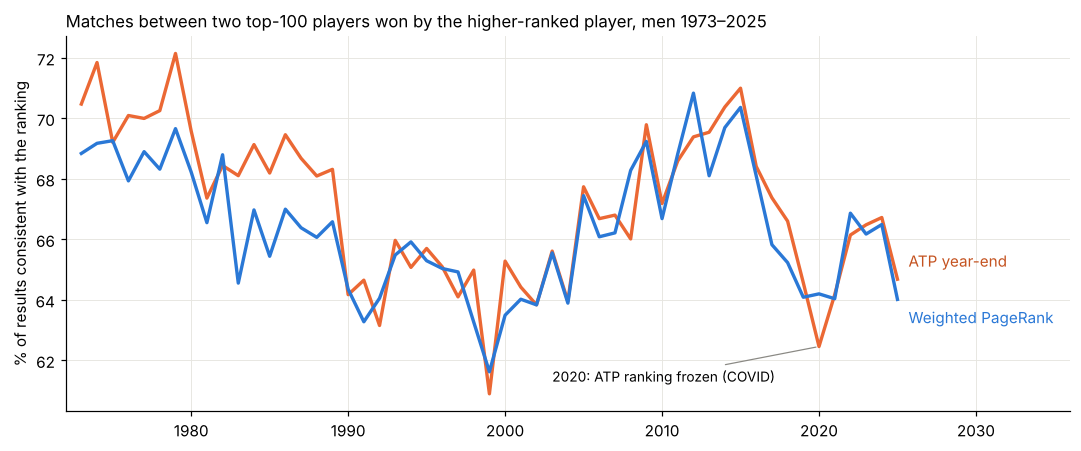

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(atp.index, atp["Official year-end"] * 100, color=ORANGE, lw=2.2)
ax.plot(atp.index, atp["Weighted PageRank"] * 100, color=BLUE, lw=2.2)
ax.text(2025.7, atp.loc[2025, "Official year-end"] * 100 + 0.6, "ATP year-end", color="#c4521f", fontsize=10, va="center")
ax.text(2025.7, atp.loc[2025, "Weighted PageRank"] * 100 - 0.6, "Weighted PageRank", color=BLUE, fontsize=10, va="center")
ax.annotate("2020: ATP ranking frozen (COVID)", (2020, atp.loc[2020, "Official year-end"] * 100), xytext=(2003, 61.3), fontsize=9,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
ax.set_xlim(1972, 2036); ax.set_ylabel("% of results consistent with the ranking")
ax.set_title("Matches between two top-100 players won by the higher-ranked player, men 1973–2025", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig("consistency_by_season.png", dpi=200); plt.show()

**What this says**
- The **ATP year-end ranking agrees with slightly more results (67.1%) than weighted PageRank (66.4%)** and standard PageRank (66.3%). The ATP ranking is ahead in most seasons, by less than one percentage point on average.
- **Most of that gap is from 1973–1989**, when the ATP ranking was an average of points per tournament: there the ATP ranking is ahead by 1.8 points. **Since 1990 the gap is only 0.2 points and not statistically significant** (p = 0.16).
- The exception is **2020**, when the ATP ranking was frozen for COVID and did not reflect that season's results; there PageRank agrees with more results.
- **Win percentage** alone gets 68.3%: a ranking that simply orders players by their record fits the season's results well. (Step 5 shows why that does not make it a better ranking.)
- The **ATP ranking published on the day of each match** gets only 63.2%: it is a forecast made before the match, while the year-end ranking already includes the result.

## Step 4 · Top 10, top 20, top 50, top 100
Does the answer change if we look only at the best players? Mean % consistent over all seasons:

In [5]:
def by_group(sizes):
    g = sizes.groupby("Group", sort=False)
    t = (g[["Official", "WPR", "Standard"]].mean() * 100).round(1)
    t["Seasons WPR higher"] = g.apply(lambda d: int((d.WPR > d.Official).sum()))
    t["Seasons official higher"] = g.apply(lambda d: int((d.Official > d.WPR).sum()))
    t["p (WPR vs official)"] = g.apply(lambda d: round(wilcoxon(d.WPR, d.Official).pvalue, 3))
    return t
by_group(atp_sizes)

,Official,WPR,Standard,Seasons WPR higher,Seasons official higher,p (WPR vs official)
Group,,,,,,
Top 10,64.4,64.3,62.0,26,24,0.787
Top 20,64.9,64.5,63.3,24,24,0.518
Top 50,65.8,65.0,64.7,15,37,0.000
Top 100,67.1,66.4,66.3,12,40,0.000


**What this says:** among the **top 10 and top 20**, weighted PageRank and the ATP ranking are **tied** (each ahead in about half of the seasons). The ATP ranking pulls ahead only when the wider field (top 50, top 100) is included. Among the top 10, weighting matters most: standard PageRank is clearly worse (62.0% against 64.3%), because the best players meet each other several times a season and only weighted PageRank counts every win.

## Step 5 · Is a higher percentage always better?
Not necessarily. A ranking can be made to fit one season's results very well without being a better ranking. To test this, I searched for the **best possible order**: the order of the top 100 with the highest percentage of consistent results (a computer search that keeps moving one player at a time to the position that adds the most consistent results). Then I checked how well each order **predicts the next season** (the same players, the next season's matches between them).

In [6]:
cols = ["Official year-end", "Weighted PageRank", "Standard PageRank", "Win percentage", "Best possible order"]
k = atp.dropna(subset=["Next: Weighted PageRank"])
summary = pd.DataFrame({"Same season (%)": atp[cols].mean() * 100,
                        "Next season (%)": k[[f"Next: {c}" for c in cols]].mean().values * 100}).round(1)
display(summary)
print(f"The best possible order predicts the next season worse than WPR in {(k['Next: Best possible order'] < k['Next: Weighted PageRank']).sum()} of {len(k)} seasons "
      f"(p = {wilcoxon(k['Next: Best possible order'], k['Next: Weighted PageRank']).pvalue:.1g})")

,Same season (%),Next season (%)
Official year-end,67.1,64.2
Weighted PageRank,66.4,64.0
Standard PageRank,66.3,63.9
Win percentage,68.3,63.9
Best possible order,76.1,62.6


The best possible order predicts the next season worse than WPR in 45 of 53 seasons (p = 1e-08)


**What this says**
- **About one match in four is an upset under any order.** Even the best possible order agrees with only about 76% of the results.
- The best possible order, and to a lesser degree win percentage, **fit this season's results but predict the next season worse** (62.6% for the best order against about 64% for the ATP ranking and PageRank). They follow luck and one-off upsets instead of the players' real level.
- So the percentage consistent is a good **description** of how well a ranking summarizes a season, but to decide which ranking is **better**, the next-season test is the fair one. There, **ATP, weighted PageRank and standard PageRank are tied (about 64%)**.

## Step 6 · Women (WTA), 1984–2025

In [7]:
wta, wta_sizes = season_table(load_wta, wta_rankings, range(1984, 2026))
kw = wta.dropna(subset=["Next: Weighted PageRank"])
print(f"Women (WTA), {len(wta)} seasons, {wta.Matches.sum():,} matches between two top-100 players")
display(pd.DataFrame({"Same season (%)": wta[cols + ['Official on match day']].mean() * 100,
                      "Next season (%)": list(kw[[f'Next: {c}' for c in cols]].mean().values * 100) + [np.nan]}).round(1))
print(f"WPR higher than the WTA year-end ranking in {(wta['Weighted PageRank'] > wta['Official year-end']).sum()} of {len(wta)} seasons "
      f"(p = {wilcoxon(wta['Weighted PageRank'], wta['Official year-end']).pvalue:.1g})")
by_group(wta_sizes)

Women (WTA), 42 seasons, 58,170 matches between two top-100 players


,Same season (%),Next season (%)
Official year-end,69.4,65.2
Weighted PageRank,68.6,64.5
Standard PageRank,68.4,64.4
Win percentage,70.4,64.9
Best possible order,78.6,64.3
Official on match day,64.6,NaN


WPR higher than the WTA year-end ranking in 8 of 42 seasons (p = 0.0007)


,Official,WPR,Standard,Seasons WPR higher,Seasons official higher,p (WPR vs official)
Group,,,,,,
Top 10,65.9,64.8,61.9,13,23,0.111
Top 20,67.8,66.4,65.2,11,28,0.006
Top 50,68.3,67.4,66.7,13,28,0.001
Top 100,69.4,68.6,68.4,8,33,0.001


**What this says:** the same picture as for men, a little stronger: the WTA ranking agrees with slightly more results than weighted PageRank (69.4% against 68.6% for the top 100), and it also predicts the next season slightly better (65.2% against 64.5%). The exception is again 2020, when the WTA ranking was frozen.

## Findings
1. **Percentage of results consistent with the order (top 100, same season):** ATP year-end 67.1%, weighted PageRank 66.4%, standard PageRank 66.3% (men); WTA 69.4%, weighted PageRank 68.6% (women). The official rankings agree with slightly more results, by less than one percentage point; for men, almost all of the gap is from before 1990, and since 1990 the difference (0.2 points) is not statistically significant.
2. **Among the best players** (top 10 and top 20 of the men), weighted PageRank and the ATP ranking are **tied**; the official ranking is ahead only for the wider field.
3. **Weighting matters among the elite:** for the top 10, standard PageRank agrees with clearly fewer results than weighted PageRank (62.0% against 64.3%), because top players meet each other repeatedly.
4. **About one result in four is an upset whatever the ranking:** the best possible order reaches only about 76% (men) and 79% (women).
5. **A higher percentage is not automatically better:** the order that fits a season best predicts the next season worse (62.6% against about 64%). For deciding which ranking is better, the next-season test is the fair one, and there the ATP ranking, weighted PageRank and standard PageRank are tied for men; for women the WTA ranking is slightly better.
6. **When the official ranking does not reflect the season** (2020, COVID freeze), PageRank agrees with more results than the official ranking.